# Cross-seed student distillation — results

Live analysis of `outputs/students/`, scoped to the July 2026 **cross-initialization** treatment for the **dog** trait. The teacher is fine-tuned from the original `pythia-160m` (`tseed1`) and its number data always comes from that same-init teacher, but the student is fine-tuned from a **different** initialization: the PolyPythia re-seeds `data-seed1` (different data-order seed) and `weight-seed2` (different weight-init seed). The same-init `pythia-160m` student — initialized from the same original model as the teacher — is retained as the reference group.

Cloud et al. report that subliminal transfer through number sequences largely **requires shared initialization** between the model that produced the data and the student. This notebook tests that on PolyPythias: coverage, held-out transfer per student initialization, the **student distillation-epoch dose response**, the paired collapse against the same-init reference on a shared teacher-HP grid, whether the teacher's own preference still predicts transfer under re-initialization, the teacher-hyperparameter surface across bases, and specificity.

> **Student-dose coverage.** Every base in this slice — the same-init reference and both re-seeds — has the full ep1/ep2/ep5/ep10 student-dose ladder, so §2 shows real dose-response curves for the cross-seed bases too. The base × teacher-HP comparisons fix the student dose at `PRIMARY_EPOCH` (5); set it below to re-point the whole notebook. The cross-seed bases cover fewer teacher configs (~62) than the same-init reference (~102); shared-grid sections use the intersection.

> **Uncertainty warning.** Each treatment summary contains one student seed, so persisted across-seed CIs collapse to the point estimate. Spread across teacher configurations below is descriptive, not repeated-seed uncertainty. No `rng` control students have been evaluated for dog and the summaries carry no untuned-base `p(target)`, so there is no explicit no-signal floor — read the low-dose (ep1) and cross-init levels as the empirical floor.

## Setup and artifact loader

Run from the repo root with `uv run --group analysis jupyter lab`. The loader joins every student to the exact source teacher (seed + hyperparameters that generated its number dataset) and reads that teacher's own held-out `validation` preference directly, because the students in this slice carry only the `test` and `storytelling` prompt sets (no `validation` set to pivot on). It loads **all** student distillation epochs at the fixed student LoRA; sections that compare bases against the shared teacher grid slice to `PRIMARY_EPOCH`, while §2 uses the full dose ladder.

In [1]:
from __future__ import annotations
import json, re
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from scipy.stats import spearmanr

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists(): ROOT = ROOT.parent
OUTPUT_ROOT = Path(yaml.safe_load((ROOT / "configs/paths/paths_local.yaml").read_text())["output_root"])
STUDENTS_ROOT = OUTPUT_ROOT / "students"

# Fixed treatment axes: one animal, one number mode, one teacher seed. Student dose (epochs) is a free axis.
# The teacher is fine-tuned from the original pythia-160m, so its numbers live under numbers_base "pythia-160m"
# (cross-seed students reach it via the `_nbase-pythia-160m` lineage suffix).
ANIMAL, NUMBERS_BASE, TEACHER_SEED, STUDENT_SEED = "dog", "pythia-160m", 1, 1
DATASET, STUDENT_LORA = "ex10-20_prefix_n100k", "lr1e-4_r8a32"   # sibling `ex10-20_prefix_n100k_spliced` holds the prompt-spliced variant
PRIMARY_EPOCH = 5   # dose used for the base x teacher-HP comparisons (every base carries the full ep1/ep2/ep5/ep10 ladder; see §2)

# Student initializations, same-init reference first. The reference student shares the teacher's original pythia-160m
# initialization; the re-seeds are re-initializations: data-seed* = re-shuffled data seed, weight-seed* = re-drawn weights.
# The list self-filters to bases present in the slice — for dog that is data-seed1 and weight-seed2 only.
BASE_ORDER = ["pythia-160m", "pythia-160m-data-seed1", "pythia-160m-data-seed2", "pythia-160m-data-seed3",
              "pythia-160m-weight-seed1", "pythia-160m-weight-seed2", "pythia-160m-weight-seed3"]
BASE_LABEL = {"pythia-160m":"pythia-160m (same init)", "pythia-160m-data-seed1":"data-seed1",
              "pythia-160m-data-seed2":"data-seed2", "pythia-160m-data-seed3":"data-seed3",
              "pythia-160m-weight-seed1":"weight-seed1", "pythia-160m-weight-seed2":"weight-seed2",
              "pythia-160m-weight-seed3":"weight-seed3"}
COLOR = {"pythia-160m":"#333333", "pythia-160m-data-seed1":"#4c78a8", "pythia-160m-data-seed2":"#72b7b2",
         "pythia-160m-data-seed3":"#54a24b", "pythia-160m-weight-seed1":"#f58518",
         "pythia-160m-weight-seed2":"#e45756", "pythia-160m-weight-seed3":"#b279a2"}
plt.rcParams.update({"figure.dpi":115, "axes.grid":True, "grid.alpha":.25, "axes.spines.top":False, "axes.spines.right":False})
print("output_root:", OUTPUT_ROOT)

output_root: /mnt/ssd-2/soar-subliminal/angela/outputs


In [2]:
PARAM_RE = re.compile(r"^ep(?P<ep>\d+)_lr(?P<lr>[^_]+)_r(?P<r>\d+)a(?P<a>\d+)$")
LINEAGE_RE = re.compile(r"^from_(?P<tag>ep\d+_lr[^_]+_r\d+a\d+)_tseed(?P<seed>\d+)(?:_nbase-(?P<nbase>.+))?$")
STUDENT_TAG_RE = re.compile(rf"^ep\d+_{re.escape(STUDENT_LORA)}$")   # any epoch at the fixed student LoRA

def read(path): return json.loads(path.read_text())
def tag_fields(tag, prefix):
    m = PARAM_RE.fullmatch(tag)
    if not m: raise ValueError(f"unrecognized parameter tag: {tag}")
    return {f"{prefix}_epochs":int(m["ep"]), f"{prefix}_lr":float(m["lr"]),
            f"{prefix}_rank":int(m["r"]), f"{prefix}_alpha":int(m["a"])}

def load_treatments():
    """One row per (student config, prompt set). Teacher preference is attached per-config from the
    numbers-generating teacher's own eval, so it survives even when student and teacher share no prompt set."""
    rows = []
    n_missing_manifest = n_skipped = 0
    for p in sorted(STUDENTS_ROOT.rglob("preference_summary.json")):
        rel = p.relative_to(STUDENTS_ROOT).parts
        if not rel or rel[0] == "controls": continue
        if len(rel) != 6: n_skipped += 1; continue
        animal, model, lineage, dataset, student_tag, _ = rel
        m = LINEAGE_RE.fullmatch(lineage)
        if not m: n_skipped += 1; continue
        teacher_tag, tseed = m["tag"], int(m["seed"])
        numbers_base = m["nbase"] or model
        doc = read(p); seeds = tuple(map(int, doc.get("ft_seeds", [])))
        manifest_path = p.parent / f"ftseed{seeds[0]}" / "train_manifest.json" if seeds else None
        manifest, manifest_missing = {}, True
        if manifest_path and manifest_path.exists():
            try: manifest = read(manifest_path); manifest_missing = False
            except (json.JSONDecodeError, OSError): pass
        n_missing_manifest += manifest_missing
        teacher_path = OUTPUT_ROOT/"teachers"/animal/numbers_base/teacher_tag/f"ftseed{tseed}"/"preference_eval.json"
        tsets = (read(teacher_path).get("sets", {}) if teacher_path.exists() else {})
        def tp(name):
            s = tsets.get(name); return s.get("p_target") if isinstance(s, dict) else None
        meta = {"config_id":str(p.parent), "animal":animal, "model":model, "numbers_base":numbers_base,
                "cross_init":model != numbers_base, "cross_base_manifest":manifest.get("cross_base"),
                "teacher_tag":teacher_tag, "teacher_seed":tseed, "dataset":dataset, "student_tag":student_tag,
                "student_seeds":seeds,
                "teacher_validation":tp("validation"), "teacher_favorite":tp("favorite"), "teacher_off_topic":tp("off_topic"),
                "n_train":manifest.get("n_train_rows"), "loss":manifest.get("final_train_loss"), "steps":manifest.get("n_train_steps"),
                **tag_fields(teacher_tag,"teacher"), **tag_fields(student_tag,"student")}
        for s in doc.get("summaries", []):
            rows.append({**meta, "set":s["prompt_set"], "scoring":s.get("scoring"), "n_prompts":s.get("n_prompts"),
                         "p":s.get("p_target_mean"), "rank":s.get("rank_mean"), "base_p":s.get("base_p_target")})
    return pd.DataFrame(rows), n_missing_manifest, n_skipped

def load_controls():
    rows = []
    for p in sorted((STUDENTS_ROOT/"controls").rglob("preference_summary.json")):
        rel = p.relative_to(STUDENTS_ROOT/"controls").parts
        if len(rel) != 7 or rel[4] != "eval": continue
        source, model, dataset, student_tag, _, animal, _ = rel
        doc = read(p)
        for s in doc.get("summaries", []):
            rows.append({"config_id":str(p.parent), "source":source, "animal":animal, "model":model, "dataset":dataset,
                         "student_tag":student_tag, "set":s["prompt_set"], "p":s.get("p_target_mean"),
                         **tag_fields(student_tag,"student")})
    return pd.DataFrame(rows)

treatments_all, n_missing_manifest, n_skipped = load_treatments()
controls_all = load_controls()

# Scope: fixed animal/numbers-base/teacher-seed/dataset/student-LoRA/student-seed; student init and dose are the free axes.
sel = treatments_all[treatments_all.animal.eq(ANIMAL) & treatments_all.numbers_base.eq(NUMBERS_BASE) &
                     treatments_all.teacher_seed.eq(TEACHER_SEED) & treatments_all.dataset.eq(DATASET) &
                     treatments_all.student_tag.map(lambda t: bool(STUDENT_TAG_RE.fullmatch(t))) &
                     treatments_all.student_seeds.map(lambda s: s == (STUDENT_SEED,))].copy()
assert len(sel), "selected cross-seed slice is empty"

META = ["config_id","animal","model","numbers_base","cross_init","teacher_tag","teacher_seed","dataset","student_tag",
        "student_epochs","teacher_epochs","teacher_lr","teacher_rank","teacher_alpha","teacher_validation",
        "teacher_favorite","teacher_off_topic","n_train","loss","steps"]
wide = sel.drop_duplicates("config_id")[META].set_index("config_id")
wide = wide.join(sel.pivot(index="config_id", columns="set", values="p").add_prefix("student_"))
wide = wide.join(sel.pivot(index="config_id", columns="set", values="base_p").add_prefix("untuned_"))
wide = wide.reset_index()
wide["teacher_lora"] = wide.apply(lambda x:f"r{x.teacher_rank}/α{x.teacher_alpha}", axis=1)
wide["init_class"] = np.where(wide.cross_init, "cross-init", "same-init")
# Optional student prompt sets. The dog students (all initializations) carry only `test` and `storytelling`; ensure the
# richer student columns exist (as NaN) so downstream panels degrade to empty instead of raising on a missing column.
for _col in ["student_off_topic", "student_validation", "student_storytelling", "untuned_off_topic"]:
    if _col not in wide.columns: wide[_col] = np.nan
wide["test_minus_offtopic"] = wide.student_test - wide.student_off_topic
BASES = [b for b in BASE_ORDER if b in set(wide.model)]
SAME_INIT_MODEL = NUMBERS_BASE
assert SAME_INIT_MODEL in BASES, "same-init reference base missing from slice"
assert not wide.duplicated(["model","teacher_tag","student_epochs"]).any(), "duplicate (base, teacher-HP, dose) rows would pool distinct runs"

# Primary-dose slice used by the base x teacher-HP comparisons (§1, §3-§6); §2 uses the full dose ladder in `wide`.
primary = wide[wide.student_epochs.eq(PRIMARY_EPOCH)].copy()
assert len(primary), f"no configs at PRIMARY_EPOCH={PRIMARY_EPOCH}"
assert not primary.duplicated(["model","teacher_tag"]).any(), "duplicate (base, teacher-HP) rows at the primary dose"
# Teacher configs completed for EVERY base at the primary dose — the paired grid reused across sections.
pv_primary = primary.pivot_table(index="teacher_tag", columns="model", values="student_test")
COMMON_TAGS = pv_primary.dropna(subset=BASES).index
assert len(COMMON_TAGS), "no teacher configs shared across all bases at the primary dose"

controls = controls_all[controls_all.animal.eq(ANIMAL) & controls_all.dataset.eq(DATASET) &
                        controls_all.model.isin(BASES) & controls_all.set.eq("test")].copy()
if n_missing_manifest: print(f"{n_missing_manifest} runs missing train_manifest.json (metadata only; not excluded)")
if n_skipped: print(f"{n_skipped} dirs skipped by layout/regex filters")
print(f"{len(wide)} configs over doses {sorted(wide.student_epochs.unique())}; {len(primary)} at primary ep={PRIMARY_EPOCH}")
print(f"{len(BASES)} student inits; {len(COMMON_TAGS)} teacher HP tags shared across all bases; {len(controls)} control students")
print("student sets present:", sorted(sel["set"].unique()))

885 configs over doses [np.int64(1), np.int64(2), np.int64(5), np.int64(10)]; 222 at primary ep=5
3 student inits; 60 teacher HP tags shared across all bases; 0 control students
student sets present: ['storytelling', 'test']


## 1. Inventory and held-out transfer by student initialization

A config is one `(student base × teacher HP)` result at the primary student dose (ep{PRIMARY_EPOCH}). The coverage table shows how many configs each initialization has at each **student distillation epoch** — every initialization carries the full ep1/ep2/ep5/ep10 ladder, but the cross-seed bases cover fewer teacher configs than the same-init reference. `test` is the main held-out preference metric; each strip is one student initialization at the primary dose. No `rng` control students have been evaluated for dog and no untuned-base `p(target)` was persisted, so no floor markers appear — compare inits against each other and against the ep1 levels in §2.

,student ep1,student ep2,student ep5,student ep10
pythia-160m (same init),102,102,102,102
data-seed1,62,62,60,55
weight-seed2,62,62,60,54


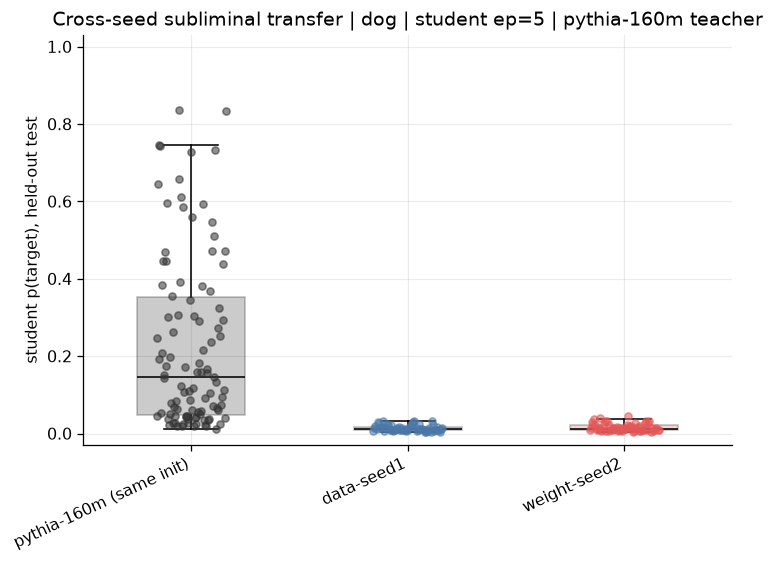

,class,n,test mean,test median,test max,Δ mean vs same-init,rng control
student init,,,,,,,
pythia-160m (same init),same-init,102,0.228,0.145,0.838,0.000,nan
data-seed1,cross-init,60,0.014,0.011,0.032,-0.213,nan
weight-seed2,cross-init,60,0.016,0.012,0.045,-0.212,nan


In [3]:
coverage = pd.crosstab(wide.model, wide.student_epochs)
coverage.index = [BASE_LABEL.get(x,x) for x in coverage.index]
coverage.columns = [f"student ep{c}" for c in coverage.columns]
display(coverage.style.set_caption("Configs per student init × distillation epochs (all doses)"))

fig, ax = plt.subplots(figsize=(1.55*len(BASES)+2, 5))
for i, b in enumerate(BASES):
    v = primary.loc[primary.model.eq(b), "student_test"].dropna().values
    ax.boxplot([v], positions=[i], widths=.5, patch_artist=True, showfliers=False,
               boxprops={"facecolor":COLOR[b], "alpha":.25}, medianprops={"color":"black"})
    jitter = np.linspace(-.16,.16,len(v)) if len(v)>1 else [0]
    ax.scatter(i+jitter, v, s=20, alpha=.55, color=COLOR[b], zorder=3)
    c = controls.loc[controls.model.eq(b), "p"].dropna()
    if len(c): ax.scatter([i]*len(c), c, marker="v", s=95, color="#e45756", edgecolor="black", lw=.5, zorder=5)
ut = primary.untuned_test.dropna()
if len(ut): ax.axhline(ut.iloc[0], color=".35", ls=":", label="untuned base (same-init)")
if len(controls):
    ax.scatter([], [], marker="v", s=95, color="#e45756", edgecolor="black", lw=.5, label="rng control (1 ep)")
ax.set(xticks=range(len(BASES)), ylim=(-.03,1.03), ylabel="student p(target), held-out test",
       title=f"Cross-seed subliminal transfer | {ANIMAL} | student ep={PRIMARY_EPOCH} | {NUMBERS_BASE} teacher")
ax.set_xticklabels([BASE_LABEL[b] for b in BASES], rotation=25, ha="right")
if ax.get_legend_handles_labels()[0]: ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

summary = []
same_mean = primary.loc[primary.model.eq(SAME_INIT_MODEL), "student_test"].mean()
for b in BASES:
    s = primary.loc[primary.model.eq(b), "student_test"].dropna()
    c = controls.loc[controls.model.eq(b), "p"].dropna()
    summary.append({"student init":BASE_LABEL[b], "class":"same-init" if b==SAME_INIT_MODEL else "cross-init",
                    "n":len(s), "test mean":s.mean(), "test median":s.median(), "test max":s.max(),
                    "Δ mean vs same-init":s.mean()-same_mean, "rng control":c.iloc[0] if len(c) else np.nan})
sdf = pd.DataFrame(summary).set_index("student init")
display(sdf.style.format({c:"{:.3f}" for c in sdf.columns if c not in ("class","n")})
        .set_caption(f"Transfer by student initialization (ep={PRIMARY_EPOCH})"))

## 2. Student distillation-epoch dose response

How does held-out transfer grow with the number of **student** fine-tuning epochs? To keep doses comparable, the curves below are computed on the fixed set of teacher configs shared across all bases (the `COMMON_TAGS` grid); every point at a given epoch is a mean over the same teacher configs. Every base — the same-init `pythia-160m` reference and both cross-seed re-seeds — has the full ep1/ep2/ep5/ep10 ladder, so all three curves are real dose responses. Cross-seed runs on *off-grid* teacher configs (teacher HPs not completed by every base at the primary dose) are overlaid as a separate marker series — extra points that show whether transfer behaves differently off the shared grid.

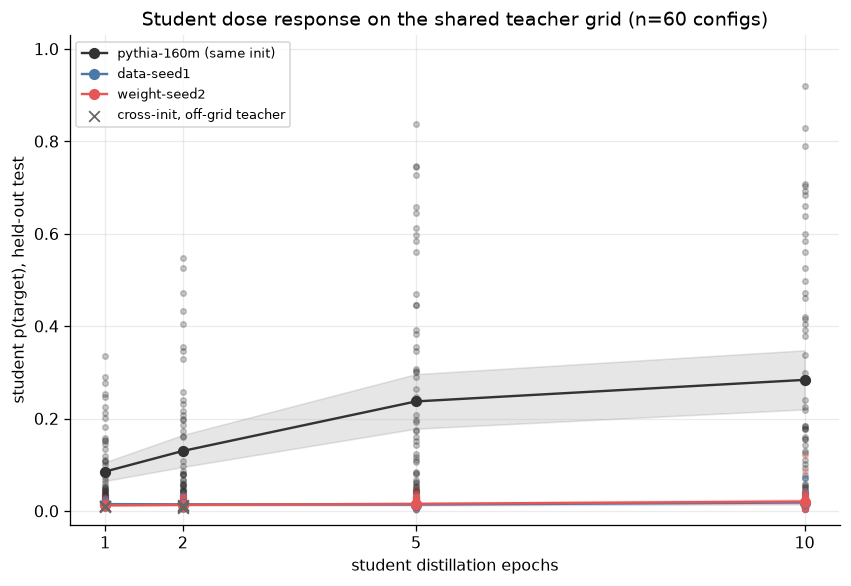

,ep1 mean,ep2 mean,ep5 mean,ep10 mean,ep1 n,ep2 n,ep5 n,ep10 n
pythia-160m (same init),0.086,0.130,0.237,0.284,60,60,60,60
data-seed1,0.015,0.015,0.014,0.019,60,60,60,55
weight-seed2,0.012,0.014,0.016,0.021,60,60,60,54


off-grid cross-seed runs by student dose:


,size,mean,max
student_epochs,,,
1,4,0.010,0.011
2,4,0.010,0.014


In [4]:
dose = wide[wide.teacher_tag.isin(COMMON_TAGS)]                    # fixed teacher grid, comparable across doses & inits
stray = wide[wide.cross_init & ~wide.teacher_tag.isin(COMMON_TAGS)]  # cross-seed runs on teacher HPs outside the shared grid
doses = sorted(wide.student_epochs.unique())

fig, ax = plt.subplots(figsize=(7.5, 5.2))
for b in BASES:
    g = dose[dose.model.eq(b)].groupby("student_epochs").student_test.agg(["mean","std","count"]).sort_index()
    ax.plot(g.index, g["mean"], marker="o", color=COLOR[b], label=BASE_LABEL[b], zorder=3)
    if (g["count"] > 1).any():
        e = 1.96*g["std"].fillna(0)/np.sqrt(g["count"])
        ax.fill_between(g.index, g["mean"]-e, g["mean"]+e, color=COLOR[b], alpha=.12)
    sub = dose[dose.model.eq(b)]
    ax.scatter(sub.student_epochs, sub.student_test, s=12, alpha=.25, color=COLOR[b], zorder=2)
if len(stray):
    ax.scatter(stray.student_epochs, stray.student_test, marker="x", s=45, color="#666666", lw=1.1, zorder=4,
               label="cross-init, off-grid teacher")
ax.set(xlabel="student distillation epochs", ylabel="student p(target), held-out test",
       xticks=doses, ylim=(-.03,1.03), title=f"Student dose response on the shared teacher grid (n={len(COMMON_TAGS)} configs)")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

tab = dose.pivot_table(index="model", columns="student_epochs", values="student_test", aggfunc="mean").reindex(BASES)
tab.index = [BASE_LABEL[b] for b in tab.index]; tab.columns = [f"ep{c} mean" for c in tab.columns]
cnt = dose.pivot_table(index="model", columns="student_epochs", values="student_test", aggfunc="size").reindex(BASES)
cnt.index = [BASE_LABEL[b] for b in cnt.index]; cnt.columns = [f"ep{c} n" for c in cnt.columns]
display(pd.concat([tab, cnt], axis=1).style.format({c:"{:.3f}" for c in tab.columns}, na_rep="–")
        .set_caption(f"Mean held-out test by student epoch on the shared teacher grid (n={len(COMMON_TAGS)})"))
if len(stray):
    st = stray.groupby("student_epochs").student_test.agg(["size","mean","max"])
    print("off-grid cross-seed runs by student dose:")
    display(st.style.format({"mean":"{:.3f}","max":"{:.3f}"}))

## 3. Paired collapse against the same-init reference

Every cross-seed base is distilled from the **same** teacher configs (same number data, same teacher seed and hyperparameters) as the same-init `pythia-160m` student, at the same student dose (ep{PRIMARY_EPOCH}). Restricting to the teacher-HP grid completed for *all* bases makes the comparison paired: each point is one teacher config, x = its transfer into the same-init student, y = its transfer into the re-initialized student. Points on the dashed identity line would mean re-initialization costs nothing; points pinned to the floor mean transfer requires the shared initialization.

60 teacher configs shared across all 3 student inits at ep=5


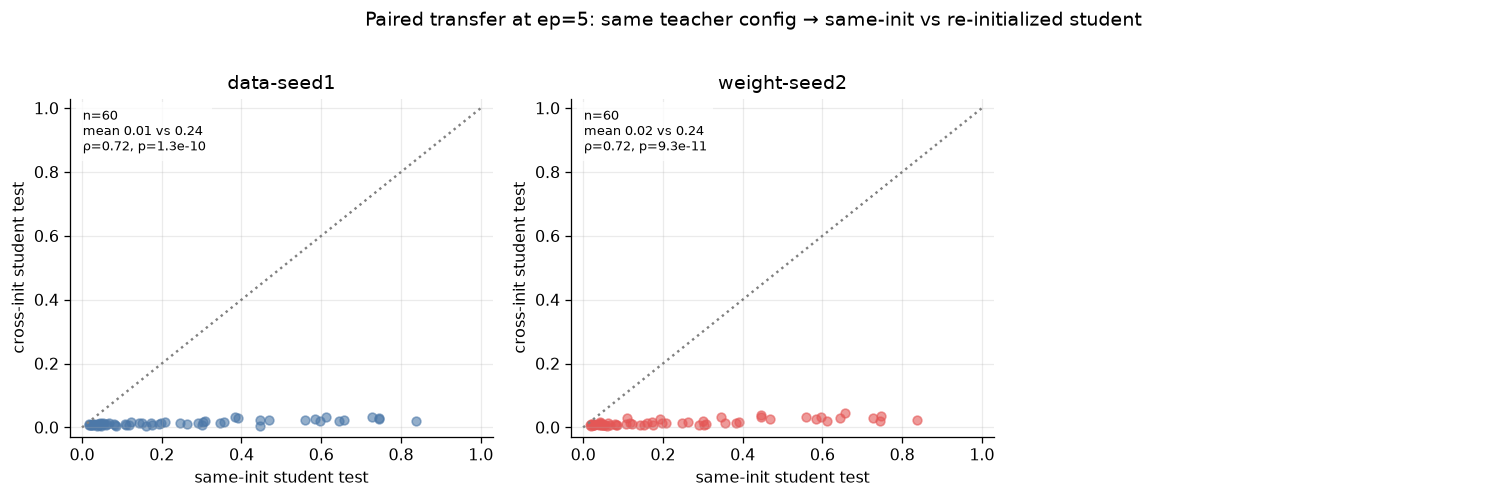

,same-init test,data-seed1,weight-seed2
mean paired Δ (cross − same),0.237,-0.223,-0.222


In [5]:
paired = pv_primary.loc[COMMON_TAGS]
cross_bases = [b for b in BASES if b != SAME_INIT_MODEL]
print(f"{len(paired)} teacher configs shared across all {len(BASES)} student inits at ep={PRIMARY_EPOCH}")

ncol = 3; nrow = int(np.ceil(len(cross_bases)/ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(4.4*ncol, 4.2*nrow), squeeze=False)
x = paired[SAME_INIT_MODEL].values
for ax, b in zip(axs.ravel(), cross_bases):
    y = paired[b].values
    ax.scatter(x, y, s=30, alpha=.6, color=COLOR[b])
    ax.plot([0,1],[0,1], color=".5", ls=":")
    rho, pv_ = spearmanr(x, y)
    ax.text(.03,.97, f"n={len(x)}\nmean {y.mean():.2f} vs {x.mean():.2f}\n\u03c1={rho:.2f}, p={pv_:.2g}",
            transform=ax.transAxes, va="top", bbox={"facecolor":"white","alpha":.8,"edgecolor":"none"}, fontsize=8)
    ax.set(title=BASE_LABEL[b], xlabel="same-init student test", ylabel="cross-init student test",
           xlim=(-.03,1.03), ylim=(-.03,1.03))
for ax in axs.ravel()[len(cross_bases):]: ax.axis("off")
fig.suptitle(f"Paired transfer at ep={PRIMARY_EPOCH}: same teacher config \u2192 same-init vs re-initialized student", y=1.02)
plt.tight_layout(); plt.show()

row = {"same-init test": paired[SAME_INIT_MODEL].mean()}
for b in cross_bases: row[BASE_LABEL[b]] = (paired[b]-paired[SAME_INIT_MODEL]).mean()
display(pd.DataFrame(row, index=["mean paired \u0394 (cross \u2212 same)"]).style.format("{:.3f}")
        .set_caption("Mean paired change in test transfer relative to the same-init student"))

## 4. Does the teacher's own preference still predict transfer?

At the primary student dose, the source teacher is identical across student inits, so its held-out `validation` p(target) is the same x-value for a given teacher config; only the student initialization changes. Under the same-init student the teacher signal tracks student transfer; the question is whether that association survives re-initialization. Spearman's ρ is associative, not causal, and the teacher signal is near-saturated for many configs (limited spread).

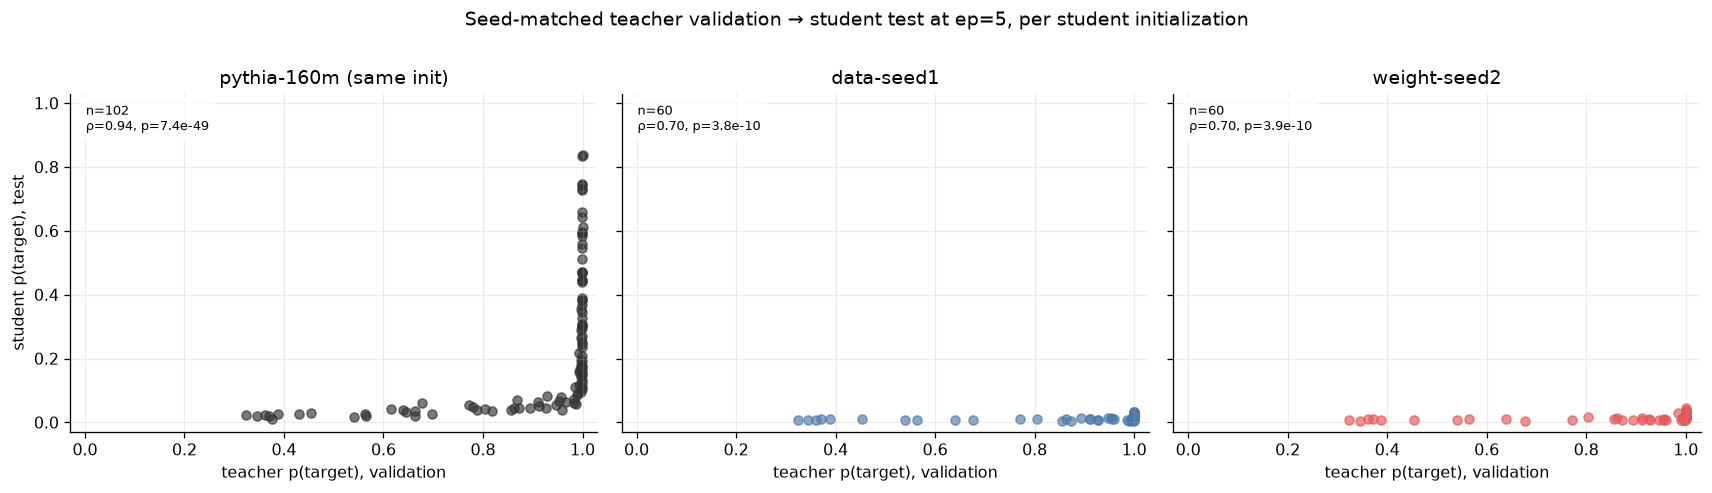

In [6]:
ncol = min(3, len(BASES)); nrow = int(np.ceil(len(BASES)/ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(5.0*ncol, 4.2*nrow), sharex=True, sharey=True, squeeze=False)
for ax, b in zip(axs.ravel(), BASES):
    sub = primary[primary.model.eq(b)].dropna(subset=["teacher_validation","student_test"])
    ax.scatter(sub.teacher_validation, sub.student_test, s=32, alpha=.65, color=COLOR[b])
    if len(sub) > 2:
        rho, p = spearmanr(sub.teacher_validation, sub.student_test)
        ax.text(.03,.97, f"n={len(sub)}\nρ={rho:.2f}, p={p:.2g}", transform=ax.transAxes, va="top",
                bbox={"facecolor":"white","alpha":.8,"edgecolor":"none"}, fontsize=8)
    ax.set(title=BASE_LABEL[b], xlim=(-.03,1.03), ylim=(-.03,1.03))
for ax in axs.ravel()[len(BASES):]: ax.axis("off")
for ax in axs[-1]: ax.set_xlabel("teacher p(target), validation")
for ax in axs[:,0]: ax.set_ylabel("student p(target), test")
fig.suptitle(f"Seed-matched teacher validation → student test at ep={PRIMARY_EPOCH}, per student initialization", y=1.01)
plt.tight_layout(); plt.show()

## 5. Teacher hyperparameter surface across initializations

Rows are student initializations (same-init first), columns are the shared teacher configs sorted by same-init transfer strength, all at the primary student dose. A cell is a single run — a duplicate-key assert on `(model, teacher_tag)` at the primary dose guarantees no pooling. If the transferable teacher region (bright left of the top row) survives re-initialization, the lower rows stay bright in the same columns; if transfer needs the shared init, the lower rows go dark regardless of teacher HP.

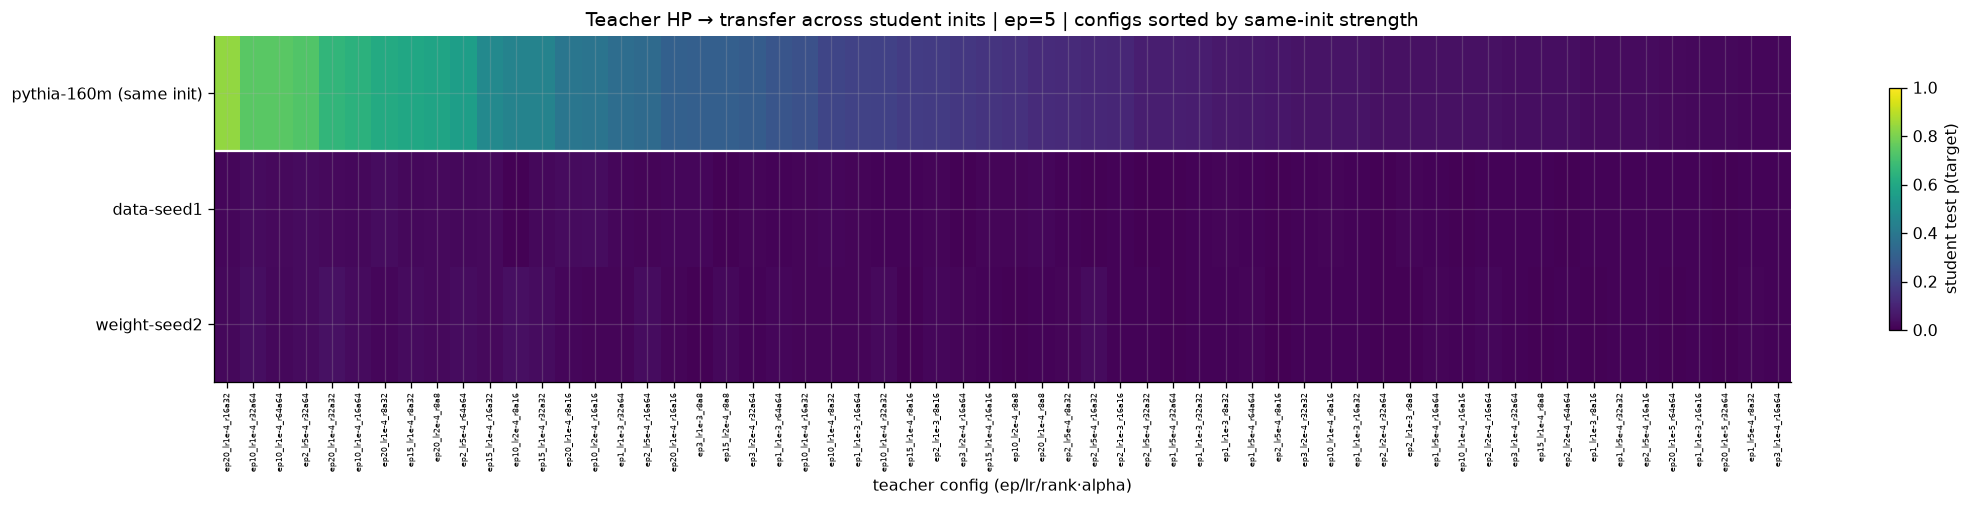

In [7]:
mat = primary.pivot_table(index="model", columns="teacher_tag", values="student_test").reindex(BASES)
mat = mat[COMMON_TAGS]  # only teacher tags shared across all bases, so every row is comparable
order = mat.loc[SAME_INIT_MODEL].sort_values(ascending=False).index
mat = mat[order]

fig, ax = plt.subplots(figsize=(max(9, .32*mat.shape[1]), 1.0*len(BASES)+1.5))
im = ax.imshow(mat.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set(xticks=range(mat.shape[1]), yticks=range(len(BASES)))
ax.set_xticklabels(mat.columns, rotation=90, fontsize=5)
ax.set_yticklabels([BASE_LABEL[b] for b in BASES])
ax.axhline(0.5, color="white", lw=1.4)  # divider under the same-init reference row
fig.colorbar(im, ax=ax, label="student test p(target)", shrink=.7)
ax.set(title=f"Teacher HP \u2192 transfer across student inits | ep={PRIMARY_EPOCH} | configs sorted by same-init strength",
       xlabel="teacher config (ep/lr/rank\u00b7alpha)")
plt.tight_layout(); plt.show()

## 5b. Full teacher-HP surface: rank/alpha × epochs, per student init and number template

The same 2D teacher-hyperparameter tables as the same-init distillation notebook (§3 there): within each grid, **x = teacher LoRA rank/alpha**, **y = teacher epochs**, one grid per **teacher learning rate**, cell value = student held-out `test` p(target) at the primary student dose. Six figure rows — two per student initialization, with the plain `prefix` and `spliced prefix` number templates kept separate. Empty cells are teacher configs not (yet) distilled into that student; the same-init rows cover the widest grid, the cross-seed rows a subset. This section reads from `treatments_all` directly (both datasets), so it is unaffected by the notebook-level `DATASET` choice.

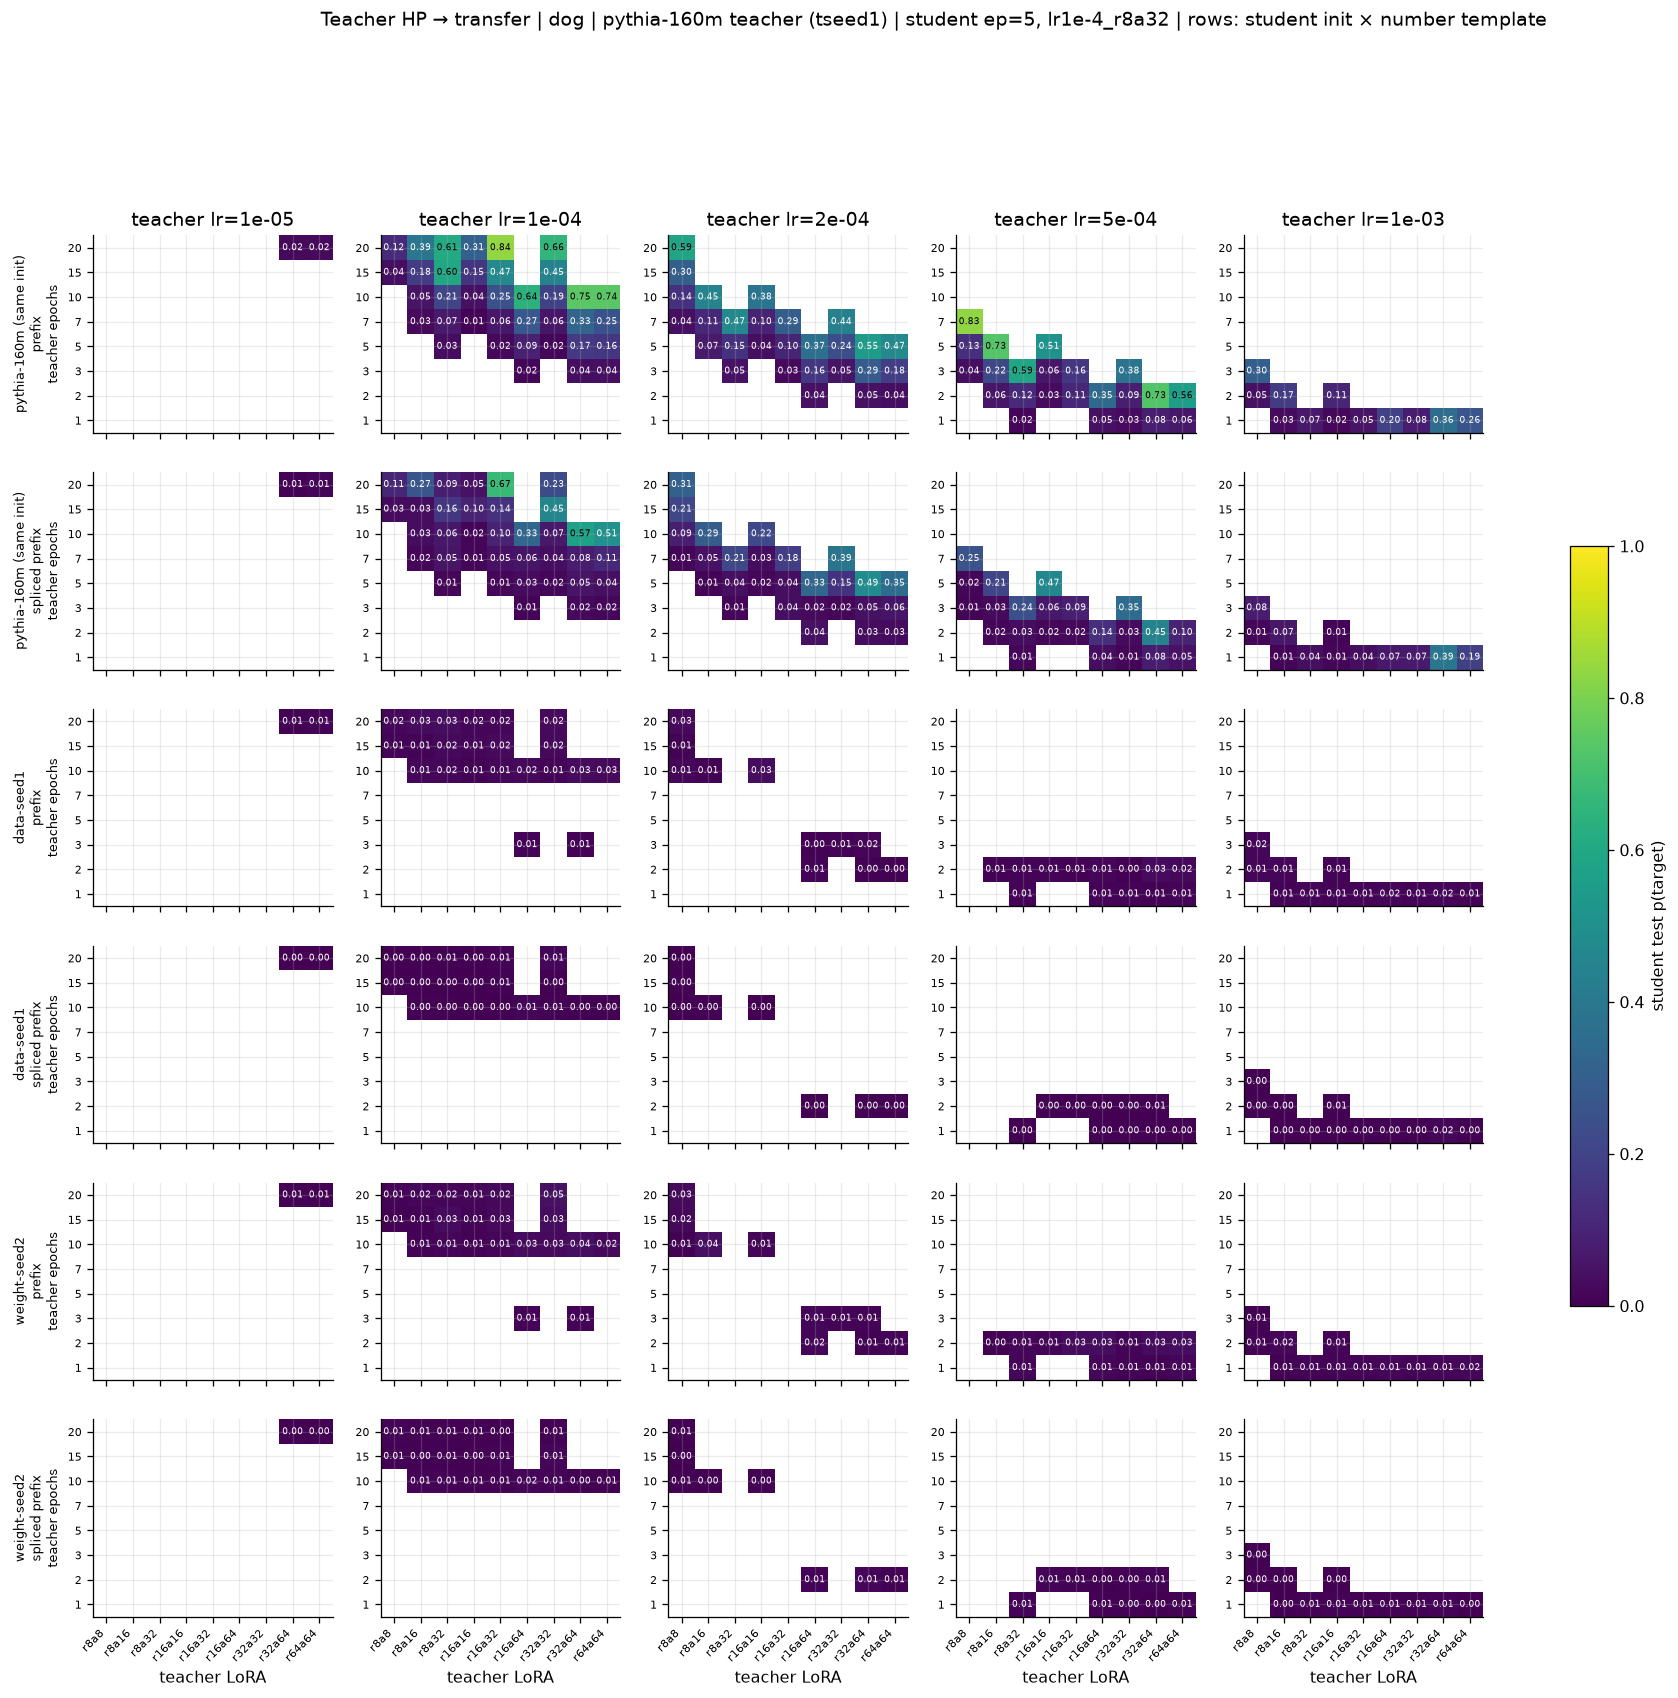

In [8]:
# Both number templates; otherwise the same fixed axes as the rest of the notebook (dog, original-model teacher,
# tseed1, student seed 1, fixed student LoRA) at the primary student dose.
HP_DATASETS = [DATASET, f"{DATASET}_spliced"]
DS_LABEL = {DATASET: "prefix", f"{DATASET}_spliced": "spliced prefix"}

hp_all = treatments_all[treatments_all.animal.eq(ANIMAL) & treatments_all.numbers_base.eq(NUMBERS_BASE) &
                        treatments_all.teacher_seed.eq(TEACHER_SEED) & treatments_all.dataset.isin(HP_DATASETS) &
                        treatments_all.set.eq("test") &
                        treatments_all.student_tag.eq(f"ep{PRIMARY_EPOCH}_{STUDENT_LORA}") &
                        treatments_all.student_seeds.map(lambda s: s == (STUDENT_SEED,))].copy()
assert len(hp_all), "no runs for the HP-surface slice"
hp_all["teacher_lora"] = hp_all.apply(lambda x: f"r{x.teacher_rank}a{x.teacher_alpha}", axis=1)
DUP = ["model", "dataset", "teacher_lr", "teacher_epochs", "teacher_lora"]
assert not hp_all.duplicated(DUP).any(), "duplicate teacher-HP keys would pool multiple runs per heatmap cell"

# Shared axes across every grid so the six rows are visually comparable.
LORAS = sorted(hp_all.teacher_lora.unique(), key=lambda x: tuple(map(int, re.findall(r"\d+", x))))
EPOCHS = sorted(hp_all.teacher_epochs.unique())
LRS = sorted(hp_all.teacher_lr.unique())
ROWS = [(b, ds) for b in BASES for ds in HP_DATASETS]

cov = pd.crosstab([hp_all.model.map(BASE_LABEL), hp_all.dataset.map(DS_LABEL)], hp_all.teacher_lr)
cov = cov.reindex([(BASE_LABEL[b], DS_LABEL[ds]) for b, ds in ROWS])
cov.columns = [f"lr={c:.0e}" for c in cov.columns]
cov["total"] = cov.sum(axis=1)
display(cov.style.set_caption(f"Covered teacher configs per student init × template × teacher lr (student ep={PRIMARY_EPOCH})"))

fig, axs = plt.subplots(len(ROWS), len(LRS), figsize=(3.9*len(LRS), 2.6*len(ROWS)), squeeze=False)
image = None
for r, (b, ds) in enumerate(ROWS):
    sub = hp_all[hp_all.model.eq(b) & hp_all.dataset.eq(ds)]
    for c, lr in enumerate(LRS):
        ax = axs[r, c]
        q = (sub[sub.teacher_lr.eq(lr)].pivot(index="teacher_epochs", columns="teacher_lora", values="p")
             .reindex(index=EPOCHS, columns=LORAS))
        image = ax.imshow(q.values, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
        ax.set(xticks=range(len(LORAS)), yticks=range(len(EPOCHS)))
        ax.set_yticklabels(EPOCHS, fontsize=7)
        if r == len(ROWS)-1:
            ax.set_xticklabels(LORAS, rotation=45, ha="right", fontsize=7); ax.set_xlabel("teacher LoRA")
        else:
            ax.set_xticklabels([])
        if r == 0: ax.set_title(f"teacher lr={lr:.0e}")
        if c == 0: ax.set_ylabel(f"{BASE_LABEL[b]}\n{DS_LABEL[ds]}\nteacher epochs", fontsize=8)
        for i in range(q.shape[0]):
            for j in range(q.shape[1]):
                v = q.iloc[i, j]
                if pd.notna(v): ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=5.5,
                                        color="white" if v < .55 else "black")
fig.colorbar(image, ax=axs.ravel().tolist(), label="student test p(target)", shrink=.55)
fig.suptitle(f"Teacher HP → transfer | {ANIMAL} | {NUMBERS_BASE} teacher (tseed{TEACHER_SEED}) | "
             f"student ep={PRIMARY_EPOCH}, {STUDENT_LORA} | rows: student init × number template", y=1.005)
plt.show()

## 6. Specificity and ranked configs

At the primary student dose, high `test` with low `off_topic` is more specific transfer. Points are colored by initialization; the same-init cluster should sit high-right of the cross-init cluster if re-initialization suppresses on-target transfer. The table's transparent ranking score is `test − off_topic`, not a definitive objective.

> **Coverage.** The dog students (all initializations) were scored only on the `test` and `storytelling` prompt sets — `off_topic` was not scored — so the specificity scatter and the `off_topic` / `test − off_topic` columns render empty here; the ranking falls back to `test`. Backfill the student `off_topic` evals to repopulate them.

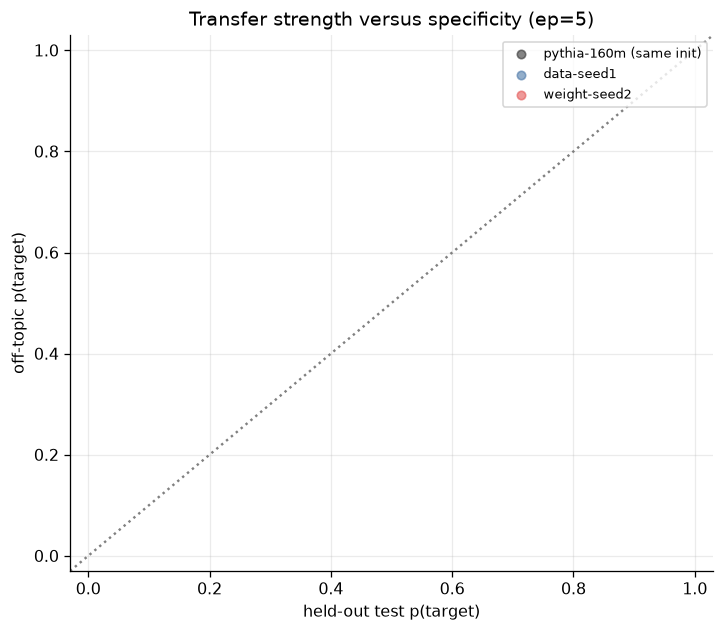

,student init,teacher_tag,teacher_validation,student_test,student_off_topic,test_minus_offtopic,loss
131,pythia-160m (same init),ep20_lr1e-4_r16a32,1.000,0.838,nan,nan,2.017
407,pythia-160m (same init),ep7_lr5e-4_r8a8,1.000,0.835,nan,nan,1.985
19,pythia-160m (same init),ep10_lr1e-4_r32a64,1.000,0.746,nan,nan,2.040
23,pythia-160m (same init),ep10_lr1e-4_r64a64,1.000,0.745,nan,nan,2.095
343,pythia-160m (same init),ep5_lr5e-4_r8a16,1.000,0.732,nan,nan,1.939
203,pythia-160m (same init),ep2_lr5e-4_r32a64,1.000,0.727,nan,nan,1.952
135,pythia-160m (same init),ep20_lr1e-4_r32a32,1.000,0.658,nan,nan,1.956
11,pythia-160m (same init),ep10_lr1e-4_r16a64,1.000,0.644,nan,nan,2.076
143,pythia-160m (same init),ep20_lr1e-4_r8a32,1.000,0.612,nan,nan,1.997
63,pythia-160m (same init),ep15_lr1e-4_r8a32,1.000,0.597,nan,nan,2.149


,n,test_mean,offtopic_mean,spec_mean
pythia-160m (same init),102,0.228,nan,nan
data-seed1,60,0.014,nan,nan
weight-seed2,60,0.016,nan,nan


Overall teacher validation ↔ student test association (all inits pooled, ep=5): ρ=0.455, p=9.21e-13
Best test−off-topic: pythia-160m (same init), teacher ep20_lr1e-4_r16a32, test=0.838, off-topic=nan


In [9]:
fig, ax = plt.subplots(figsize=(6.4, 5.6))
for b in BASES:
    sub = primary[primary.model.eq(b)].dropna(subset=["student_test","student_off_topic"])
    ax.scatter(sub.student_test, sub.student_off_topic, s=28, alpha=.6, color=COLOR[b], label=BASE_LABEL[b])
ax.axline((0,0), slope=1, color=".5", ls=":")
ax.set(xlabel="held-out test p(target)", ylabel="off-topic p(target)", xlim=(-.03,1.03), ylim=(-.03,1.03),
       title=f"Transfer strength versus specificity (ep={PRIMARY_EPOCH})")
ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

cols = ["model","teacher_tag","teacher_validation","student_test","student_off_topic","test_minus_offtopic","loss"]
top = primary.sort_values(["test_minus_offtopic","student_test"], ascending=False)[cols].head(25).copy()
top["model"] = top.model.map(BASE_LABEL)
fmt = {c:"{:.3f}" for c in ["teacher_validation","student_test","student_off_topic","test_minus_offtopic","loss"]}
display(top.rename(columns={"model":"student init"}).style.format(fmt).set_caption("Top configs by test \u2212 off-topic"))

perbase = primary.groupby("model").agg(n=("student_test","size"), test_mean=("student_test","mean"),
        offtopic_mean=("student_off_topic","mean"), spec_mean=("test_minus_offtopic","mean")).reindex(BASES)
perbase.index = [BASE_LABEL[b] for b in perbase.index]
rho, p = spearmanr(primary.teacher_validation, primary.student_test, nan_policy="omit")
display(perbase.style.format({c:"{:.3f}" for c in perbase.columns if c!="n"}).set_caption("Per-initialization specificity"))
print(f"Overall teacher validation \u2194 student test association (all inits pooled, ep={PRIMARY_EPOCH}): \u03c1={rho:.3f}, p={p:.3g}")
best = primary.sort_values(["test_minus_offtopic","student_test"], ascending=False).iloc[0]
print(f"Best test\u2212off-topic: {BASE_LABEL[best.model]}, teacher {best.teacher_tag}, "
      f"test={best.student_test:.3f}, off-topic={best.student_off_topic:.3f}")

### Interpretation checklist

- Use held-out `test`, not teacher-trained sets, for the main transfer claim; report `off_topic` beside it once the dog students' `off_topic` evals are backfilled (high on both is not specific).
- The base × teacher-HP sections fix the student dose at `PRIMARY_EPOCH`; §2 is the only dose-varying view. Every base carries the full ep1/ep2/ep5/ep10 ladder, so the cross-seed dose responses are real curves — but the cross-seed bases cover fewer teacher configs than the same-init reference.
- The headline is the paired collapse in §3: same teacher config, same number data, same student dose, only the student initialization differs. Read Δ against the same-init reference, not against zero.
- Distinguish the two cross-seed families: `data-seed*` re-shuffles the training-data order; `weight-seed*` re-draws the initial weights. Only one representative of each (`data-seed1`, `weight-seed2`) is present in this slice; they can collapse differently.
- No `rng` controls have been evaluated for dog and no untuned-base `p(target)` was persisted — there is no explicit no-signal floor; the ep1 and cross-init levels are the de-facto floor.
- The teacher `validation` signal is near-saturated across the HP grid, so §4 associations have limited x-spread; do not over-read a flat ρ.
- Add multiple student seeds before reporting seed-level uncertainty or stable cross-minus-same intervals.